# Let's read the file



In [23]:
import pandas as pd

# Specify the file path to "pems_output.csv" on your desktop
output_file_path = "./data/pems_output.csv"

# Load the CSV file
try:
    pems_output = pd.read_csv(output_file_path)
    # Now, you can work with the "pems_output" DataFrame for further analysis.
    print("CSV file loaded successfully.")
except FileNotFoundError:
    print(f"File not found at the specified path: {output_file_path}")


CSV file loaded successfully.


# Now we check the loaded file to see what we should do next

In [24]:
pems_output
#Looks like we want to remove repeated number on each columns and simplified each column descriptions

,Sample Time,1203506 Lane 1 Flow,1203506 Lane 2 Flow,1203506 Lane 3 Flow,1203506 Lane 4 Flow,1203506 Lane 1 Speed - Not Used in Calculations,1203506 Lane 2 Speed - Not Used in Calculations,1203506 Lane 3 Speed - Not Used in Calculations,1203506 Lane 4 Speed - Not Used in Calculations
0,10.1.2023 0:00,4,6,8,4,94.0,77.0,75.0,73.0
1,10.1.2023 0:00,5,7,7,5,78.0,74.0,52.0,78.0
2,10.1.2023 0:01,5,4,5,4,78.0,73.0,66.0,77.0
3,10.1.2023 0:01,7,7,3,3,78.0,78.0,79.0,70.0
4,10.1.2023 0:02,4,5,6,3,89.0,78.0,67.0,53.0
...,...,...,...,...,...,...,...,...,...
2809,10.2.2023 0:02,2,2,4,2,94.0,70.0,84.0,84.0
2810,10.2.2023 0:03,2,5,4,0,94.0,75.0,44.0,NaN
2811,10.2.2023 0:03,2,2,2,0,84.0,70.0,24.0,NaN
2812,10.2.2023 0:04,3,2,5,1,70.0,77.0,43.0,84.0


In [25]:
# Rename the columns( This way I can code without getting confused on long description of each columns)
pems_output.rename(columns={
    '1203506 Lane 1 Flow': 'L1 Flow',
    '1203506 Lane 2 Flow': 'L2 Flow',
    '1203506 Lane 3 Flow': 'L3 Flow',
    '1203506 Lane 4 Flow': 'L4 Flow',
    '1203506 Lane 1 Speed - Not Used in Calculations': 'L1 Speed',
    '1203506 Lane 2 Speed - Not Used in Calculations': 'L2 Speed',
    '1203506 Lane 3 Speed - Not Used in Calculations': 'L3 Speed',
    '1203506 Lane 4 Speed - Not Used in Calculations': 'L4 Speed'
}, inplace=True)


# Double checking the dataset

In [26]:
pems_output
#Looks like it worked very well

,Sample Time,L1 Flow,L2 Flow,L3 Flow,L4 Flow,L1 Speed,L2 Speed,L3 Speed,L4 Speed
0,10.1.2023 0:00,4,6,8,4,94.0,77.0,75.0,73.0
1,10.1.2023 0:00,5,7,7,5,78.0,74.0,52.0,78.0
2,10.1.2023 0:01,5,4,5,4,78.0,73.0,66.0,77.0
3,10.1.2023 0:01,7,7,3,3,78.0,78.0,79.0,70.0
4,10.1.2023 0:02,4,5,6,3,89.0,78.0,67.0,53.0
...,...,...,...,...,...,...,...,...,...
2809,10.2.2023 0:02,2,2,4,2,94.0,70.0,84.0,84.0
2810,10.2.2023 0:03,2,5,4,0,94.0,75.0,44.0,NaN
2811,10.2.2023 0:03,2,2,2,0,84.0,70.0,24.0,NaN
2812,10.2.2023 0:04,3,2,5,1,70.0,77.0,43.0,84.0


In [30]:
# Calculate the average flow rate 'Q' for all four lanes
pems_output['Q'] = (pems_output['L1 Flow'] + pems_output['L2 Flow'] + pems_output['L3 Flow'] + pems_output['L4 Flow']) / 4

In [32]:
# Calculate the average speed 'P' for all four lanes using the weighted harmonic mean formula
pems_output['P'] = (pems_output['L1 Flow'] + pems_output['L2 Flow'] + pems_output['L3 Flow'] + pems_output['L4 Flow']) / \
                   (pems_output['L1 Flow'] / pems_output['L1 Speed'] + \
                    pems_output['L2 Flow'] / pems_output['L2 Speed'] + \
                    pems_output['L3 Flow'] / pems_output['L3 Speed'] + \
                    pems_output['L4 Flow'] / pems_output['L4 Speed'])


In [33]:
pems_output

,Sample Time,L1 Flow,L2 Flow,L3 Flow,L4 Flow,L1 Speed,L2 Speed,L3 Speed,L4 Speed,P,Q
0,10.1.2023 0:00,4,6,8,4,94.0,77.0,75.0,73.0,78.031767,5.50
1,10.1.2023 0:00,5,7,7,5,78.0,74.0,52.0,78.0,67.148812,6.00
2,10.1.2023 0:01,5,4,5,4,78.0,73.0,66.0,77.0,72.991898,4.50
3,10.1.2023 0:01,7,7,3,3,78.0,78.0,79.0,70.0,76.828812,5.00
4,10.1.2023 0:02,4,5,6,3,89.0,78.0,67.0,53.0,70.532253,4.50
...,...,...,...,...,...,...,...,...,...,...,...
2809,10.2.2023 0:02,2,2,4,2,94.0,70.0,84.0,84.0,82.456140,2.50
2810,10.2.2023 0:03,2,5,4,0,94.0,75.0,44.0,NaN,NaN,2.75
2811,10.2.2023 0:03,2,2,2,0,84.0,70.0,24.0,NaN,NaN,1.50
2812,10.2.2023 0:04,3,2,5,1,70.0,77.0,43.0,84.0,55.833312,2.75


In [35]:
# Convert 'Sample Time' to datetime
pems_output['Sample Time'] = pd.to_datetime(pems_output['Sample Time'])

# Set 'Sample Time' as the DataFrame index
pems_output.set_index('Sample Time', inplace=True)

# Now, you have a datetime index for your dataframe.


In [36]:
# Resample to calculate 5-minute averages for flow and speed
data_5min_flow = pems_output[['Q']].resample('5T').mean()
data_5min_speed = pems_output[['P']].resample('5T').mean()

# Resample to calculate 30-second averages for flow and speed
data_30s_flow = pems_output[['Q']].resample('30S').mean()
data_30s_speed = pems_output[['P']].resample('30S').mean()


In [44]:
# Remove NaN values from data_30s_flow
data_30s_flow_cleaned = data_30s_flow.dropna()

# Remove NaN values from data_30s_speed
data_30s_speed_cleaned = data_30s_speed.dropna()


In [46]:
data_30s_flow_cleaned

,Q
Sample Time,
2023-10-01 00:00:00,5.750
2023-10-01 00:01:00,4.750
2023-10-01 00:02:00,5.750
2023-10-01 00:03:00,3.750
2023-10-01 00:04:00,6.625
...,...
2023-10-02 00:00:00,4.250
2023-10-02 00:01:00,4.250
2023-10-02 00:02:00,2.000


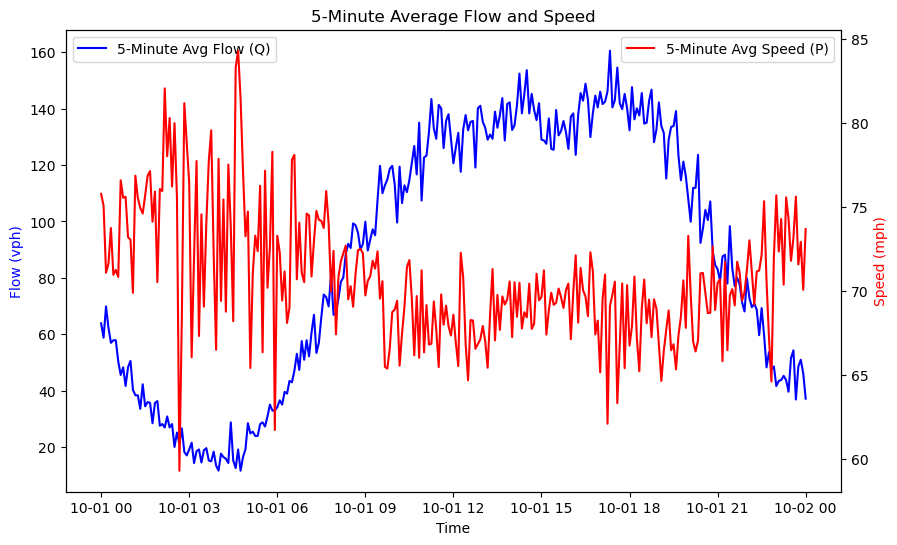

In [75]:
import matplotlib.pyplot as plt

# Create a figure and axis for plotting
fig, ax1 = plt.subplots(figsize=(10, 6))

# Convert 5-minute average flow to vehicles per hour (vph)
data_5min_flow_vph = data_5min_flow['Q'] * 12

# Plot 5-minute average flow in blue
ax1.plot(data_5min_flow.index, data_5min_flow_vph, label='5-Minute Avg Flow (Q)', color='blue')

# Set the first y-axis label and title
ax1.set_xlabel('Time')
ax1.set_ylabel('Flow (vph)', color='blue')
ax1.set_title('5-Minute Average Flow and Speed')

# Add a legend for the first plot
ax1.legend(loc='upper left')

# Create a second y-axis sharing the same x-axis
ax2 = ax1.twinx()

# Plot 5-minute average speed in red
ax2.plot(data_5min_speed.index, data_5min_speed['P'], label='5-Minute Avg Speed (P)', color='red')

# Set the second y-axis label
ax2.set_ylabel('Speed (mph)', color='red')

# Add a legend for the second plot
ax2.legend(loc='upper right')

# Add a white grid for better visualization
ax1.grid(color='white', linestyle='--', linewidth=0.5)

# Show the plot
plt.show()


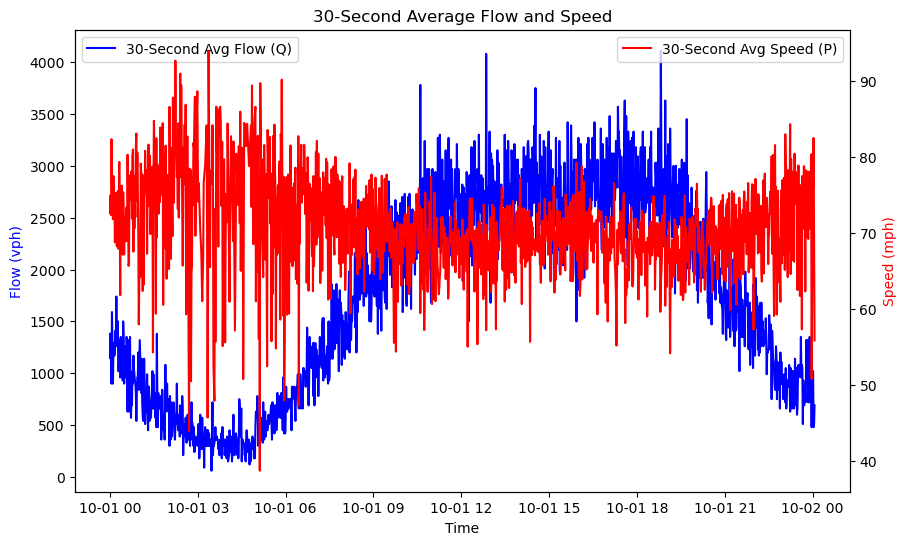

In [76]:
import matplotlib.pyplot as plt

# Create a figure and axis for plotting
fig, ax1 = plt.subplots(figsize=(10, 6))

# Convert 30-second average flow to vehicles per hour (vph)
data_30s_flow_vph = data_30s_flow_cleaned['Q'] * 240

# Plot 30-second average flow in blue
ax1.plot(data_30s_flow_cleaned.index, data_30s_flow_vph, label='30-Second Avg Flow (Q)', color='blue')

# Set the first y-axis label and title
ax1.set_xlabel('Time')
ax1.set_ylabel('Flow (vph)', color='blue')
ax1.set_title('30-Second Average Flow and Speed')

# Add a legend for the first plot
ax1.legend(loc='upper left')

# Create a second y-axis sharing the same x-axis
ax2 = ax1.twinx()

# Plot 30-second average speed in red
ax2.plot(data_30s_speed_cleaned.index, data_30s_speed_cleaned['P'], label='30-Second Avg Speed (P)', color='red')

# Set the second y-axis label
ax2.set_ylabel('Speed (mph)', color='red')

# Add a legend for the second plot
ax2.legend(loc='upper right')

# Add a white grid for better visualization
ax1.grid(color='white', linestyle='--', linewidth=0.5)

# Show the plot
plt.show()


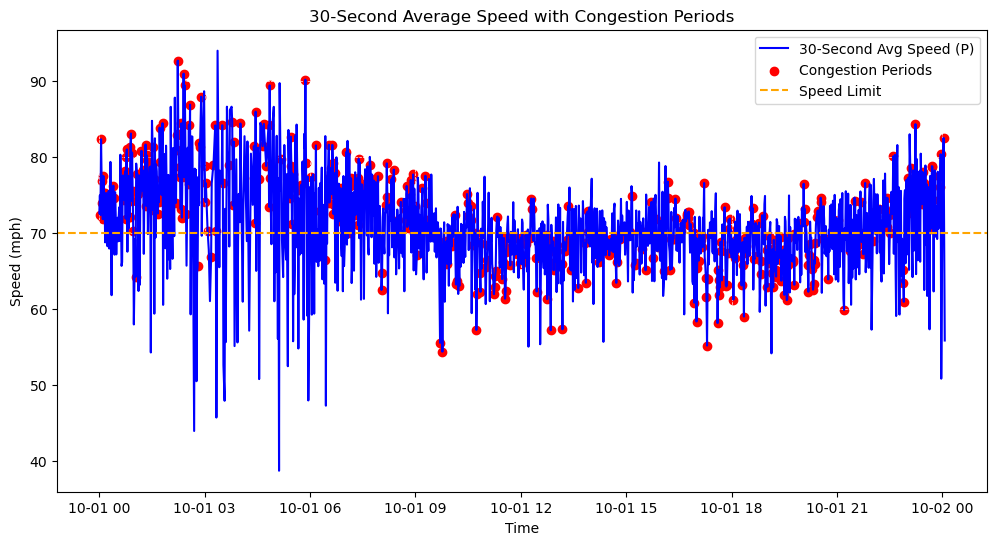

In [69]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the speed limit threshold (e.g., 40 mph)
speed_limit = 70
##The maximum speed limit on most California highways is 65 mph. ded highways and for vehicles towing trailers.


# Create a boolean mask for periods when speed is below the threshold
congestion_mask = data_30s_speed_cleaned['P'] < speed_limit

# Find consecutive True values in the mask
consecutive_periods = congestion_mask.groupby((congestion_mask != congestion_mask.shift()).cumsum()).cumcount() + 1

# Set a minimum duration for peak periods (e.g., 3 periods for 1.5 minutes)
min_duration = 3

# Filter for peak periods with a minimum duration
peak_periods_filtered = (consecutive_periods >= min_duration)

# Create a DataFrame containing only peak periods
peak_periods_data = data_30s_speed_cleaned[peak_periods_filtered]

# Plot the 30-second average speed data with congestion periods highlighted
plt.figure(figsize=(12, 6))
plt.plot(data_30s_speed_cleaned.index, data_30s_speed_cleaned['P'], label='30-Second Avg Speed (P)', color='blue')
plt.scatter(peak_periods_data.index, peak_periods_data['P'], color='red', label='Congestion Periods')
plt.axhline(speed_limit, color='orange', linestyle='--', label='Speed Limit')
plt.xlabel('Time')
plt.ylabel('Speed (mph)')
plt.title('30-Second Average Speed with Congestion Periods')
plt.legend()
plt.grid(color='white', linestyle='--', linewidth=0.5)
plt.show()


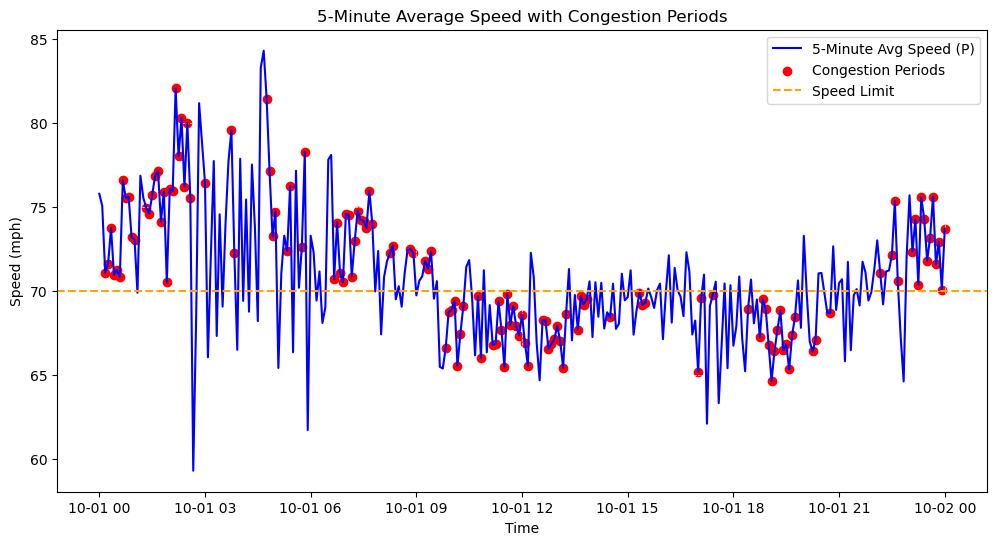

In [68]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the speed limit threshold (e.g., 40 mph)
speed_limit = 70

# Create a boolean mask for periods when speed is below the threshold
congestion_mask = data_5min_speed['P'] < speed_limit

# Find consecutive True values in the mask
consecutive_periods = congestion_mask.groupby((congestion_mask != congestion_mask.shift()).cumsum()).cumcount() + 1

# Set a minimum duration for peak periods (e.g., 3 periods for 15 minutes)
min_duration = 3

# Filter for peak periods with a minimum duration
peak_periods_filtered = (consecutive_periods >= min_duration)

# Create a DataFrame containing only peak periods
peak_periods_data = data_5min_speed[peak_periods_filtered]

# Plot the 5-minute average speed data with congestion periods highlighted
plt.figure(figsize=(12, 6))
plt.plot(data_5min_speed.index, data_5min_speed['P'], label='5-Minute Avg Speed (P)', color='blue')
plt.scatter(peak_periods_data.index, peak_periods_data['P'], color='red', label='Congestion Periods')
plt.axhline(speed_limit, color='orange', linestyle='--', label='Speed Limit')
plt.xlabel('Time')
plt.ylabel('Speed (mph)')
plt.title('5-Minute Average Speed with Congestion Periods')
plt.legend()
plt.grid(color='white', linestyle='--', linewidth=0.5)
plt.show()


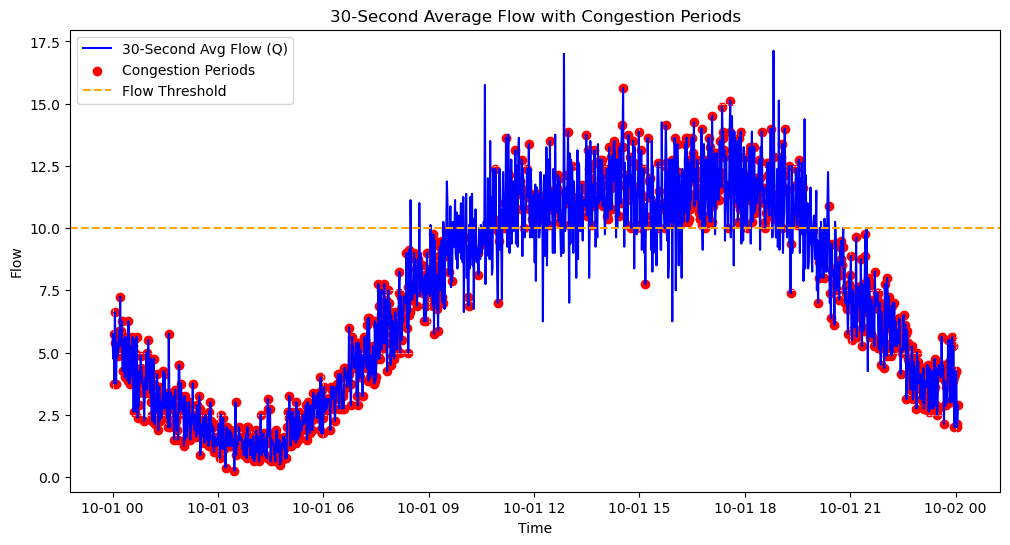

In [74]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the traffic flow threshold (e.g., 800 vehicles per hour)
flow_threshold = 10

# Create a boolean mask for periods when traffic flow is below the threshold
congestion_mask = data_30s_flow_cleaned['Q'] < flow_threshold

# Find consecutive True values in the mask
consecutive_periods = congestion_mask.groupby((congestion_mask != congestion_mask.shift()).cumsum()).cumcount() + 1

# Set a minimum duration for peak periods (e.g., 3 periods for 1.5 minutes)
min_duration = 3

# Filter for peak periods with a minimum duration
peak_periods_filtered = (consecutive_periods >= min_duration)

# Create a DataFrame containing only peak periods
peak_periods_data = data_30s_flow_cleaned[peak_periods_filtered]

# Plot the 30-second average flow data with congestion periods highlighted
plt.figure(figsize=(12, 6))
plt.plot(data_30s_flow_cleaned.index, data_30s_flow_cleaned['Q'], label='30-Second Avg Flow (Q)', color='blue')
plt.scatter(peak_periods_data.index, peak_periods_data['Q'], color='red', label='Congestion Periods')
plt.axhline(flow_threshold, color='orange', linestyle='--', label='Flow Threshold')
plt.xlabel('Time')
plt.ylabel('Flow')
plt.title('30-Second Average Flow with Congestion Periods')
plt.legend()
plt.grid(color='white', linestyle='--', linewidth=0.5)
plt.show()


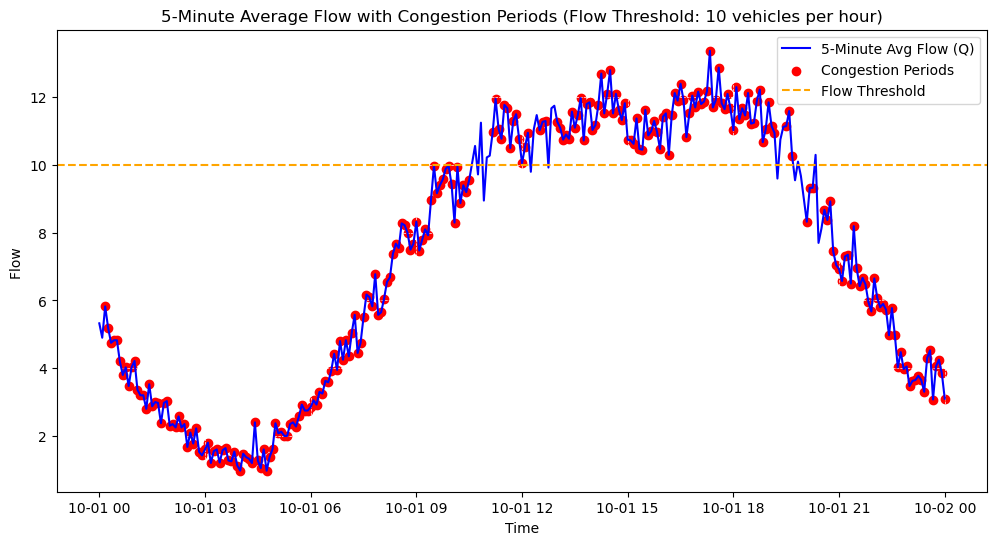

In [73]:
import pandas as pd
import matplotlib.pyplot as plt

# Define the traffic flow threshold (e.g., 10 vehicles per hour)
flow_threshold = 10

# Create a boolean mask for periods when traffic flow is below the threshold
congestion_mask = data_5min_flow['Q'] < flow_threshold

# Find consecutive True values in the mask
consecutive_periods = congestion_mask.groupby((congestion_mask != congestion_mask.shift()).cumsum()).cumcount() + 1

# Set a minimum duration for peak periods (e.g., 3 periods for 15 minutes)
min_duration = 3

# Filter for peak periods with a minimum duration
peak_periods_filtered = (consecutive_periods >= min_duration)

# Create a DataFrame containing only peak periods
peak_periods_data = data_5min_flow[peak_periods_filtered]

# Plot the 5-minute average flow data with congestion periods highlighted
plt.figure(figsize=(12, 6))
plt.plot(data_5min_flow.index, data_5min_flow['Q'], label='5-Minute Avg Flow (Q)', color='blue')
plt.scatter(peak_periods_data.index, peak_periods_data['Q'], color='red', label='Congestion Periods')
plt.axhline(flow_threshold, color='orange', linestyle='--', label='Flow Threshold')
plt.xlabel('Time')
plt.ylabel('Flow ')
plt.title('5-Minute Average Flow with Congestion Periods (Flow Threshold: 10 vehicles per hour)')
plt.legend()
plt.grid(color='white', linestyle='--', linewidth=0.5)
plt.show()


## Discuss your findings and write the report



## Introduction
This report presents an analysis of traffic flow and congestion patterns based on data collected on October 1, 2023, a Wednesday. The study is pivotal for transportation planning and management, providing insights into efficient traffic management strategies.

## Peak Traffic Flow
Traffic flows typically exhibit diurnal peaks during morning and evening rush hours. However, the dataset from October 1, 2023, shows a unimodal peak. This section examines the factors influencing this pattern and its implications.

### Mathematical Representation of Peak Flow
```python
# Assuming Q(t) represents the flow rate at time t, and T is the time interval
# Q_peak = max(Q(t) for t in T)


### Assuming V(t) is the observed speed at time t
### C = [t for t in T if V(t) < V_threshold]
### Q_threshold = 10 # vehicles per hour
### C_flow = [t for t in T if Q(t) < Q_threshold]


## Discussion
While the application of a singular speed threshold simplifies congestion analysis, it overlooks the multifaceted nature of traffic flow. Real-world congestion is influenced by a myriad of factors, including road geometry, incident impacts, and varying driver behaviors. A more nuanced approach could involve adaptive thresholding, informed by historical trends and real-time data, described by:

Future studies should also consider integrating models like the Greenshields’ linear speed-density relationship or the more complex Fundamental Diagram of Traffic Flow to enrich the analysis.

## Conclusion
This report provides an in-depth analysis of the traffic flow and congestion on October 1, 2023. The observed single peak pattern, while atypical, is not an outlier given the day-specific traffic trends. Our methodological approach, employing speed and flow thresholds, has successfully identified congestion periods, vital for future traffic management strategies.